# Forklift load volume - run top to bottom
Runs from the repo root. The video is not in the repo: `yt-dlp` downloads it if `video.mp4` is missing. Clicked points are in `outputs/points_*.json` (clicked by hand with `src/annotate.py`).
**D (3 EUR pallets) is most likely, not proven**: the number and type of pallets and the depth are unverified, see README. Mast clicks: `outputs/points_mast.json` (`src/annotate_mast.py`).

In [1]:
import os, subprocess, sys, json
os.chdir(os.path.abspath('..') if os.path.basename(os.getcwd())=='notebooks' else os.getcwd())
sys.path.insert(0, 'src')
env = dict(os.environ, PYTHONPATH='src', MPLBACKEND='Agg')
def run(*a):
    p = subprocess.run([sys.executable, *a], env=env, capture_output=True, text=True); print(p.stdout[-3000:])
    if p.returncode: raise RuntimeError(f"{a} failed:\n{p.stderr[-2000:]}")

## 1. Video and frames
Frames of the pass (21.7-22 s) are already in `frames/`. Re-download only if you want to rebuild them: `yt-dlp -f 'bv*[height<=1080]' -o video.mp4 https://www.youtube.com/watch?v=RCqa8Kojlw8`, then `python src/extract_frames.py`.

In [2]:
print(sorted(os.listdir('frames'))[:12])

['A_00999.jpg', 'A_01014.jpg', 'A_01050.jpg', 'A_01056.jpg', 'A_01062.jpg', 'A_01068.jpg', 'A_01086.jpg', 'A_01092.jpg', 'A_01098.jpg', 'A_01122.jpg', 'A_01128.jpg', 'A_01134.jpg']


## 2. Clicked points drawn on frame #1092

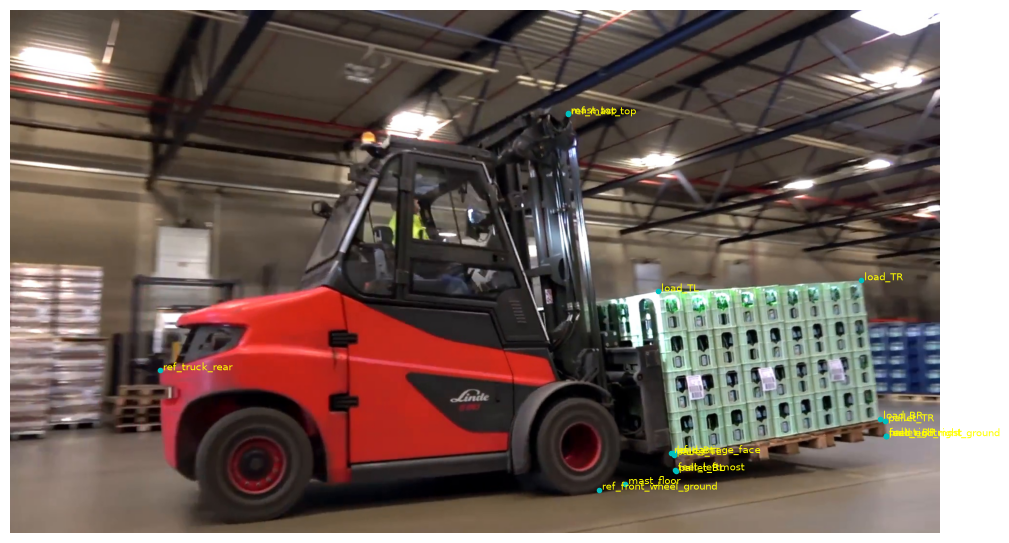

In [3]:
import cv2, numpy as np, matplotlib.pyplot as plt
from measure import load_points
P = load_points()['1092']
im = cv2.cvtColor(cv2.imread('frames/A_01092.jpg'), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(12, 6.8)); plt.imshow(im)
for k, v in P.items(): plt.plot(*v, 'c.'); plt.text(v[0] + 6, v[1], k, color='yellow', fontsize=7)
plt.axis('off'); plt.show()

## 3a. Which mast? Mast/roof ratio and tyres (clicks in `outputs/points_mast.json`, tool `src/annotate_mast.py`)
The truck has the 3213 mm mast (h1/h6 = 1.132), not the 2888 mm one. All truck-scale numbers below use 3213 mm.

In [4]:
run('src/mast_check.py')


== A_01086.jpg ==
  px: mast 794, roof 754, front tyre 207.9, rear tyre 241.1
  mast/roof raw 1.053 -> perspective-corrected 1.128 (80 %: 1.106-1.150)  -> best mast 3213 mm
  mast/front tyre raw 3.82;  front/rear tyre 0.862
  tyre scale: mast 3164 mm (80 %: 3073-3254), roof 2806 mm (datasheet 2838, check 0.989) -> best mast 3213 mm

== A_01092.jpg ==
  px: mast 765, roof 723, front tyre 198.1, rear tyre 233.3
  mast/roof raw 1.058 -> perspective-corrected 1.130 (80 %: 1.109-1.151)  -> best mast 3213 mm
  mast/front tyre raw 3.86;  front/rear tyre 0.849
  tyre scale: mast 3191 mm (80 %: 3097-3284), roof 2825 mm (datasheet 2838, check 0.995) -> best mast 3213 mm

== A_01098.jpg ==
  px: mast 733, roof 702, front tyre 191.5, rear tyre 230.7
  mast/roof raw 1.043 -> perspective-corrected 1.130 (80 %: 1.108-1.154)  -> best mast 3213 mm
  mast/front tyre raw 3.83;  front/rear tyre 0.830
  tyre scale: mast 3177 mm (80 %: 3077-3276), roof 2811 mm (datasheet 2838, check 0.991) -> best mast 321

## 3. Scales, heights and lengths per frame (plain arithmetic on the clicks)

In [5]:
run('src/measure.py')

oad face 1.165;  case C pieces: {'pallet144/f800': (1.97, 0.56, 16), 'pallet144/f1400': (1.97, 0.99, 27), 'truck/f800': (1.94, 0.55, 16), 'truck/f1400': (1.94, 0.97, 27)} (Lx m, dZ m, turn deg)
homography, load face in mm: {'A one EUR pallet': (1112, 1314), 'B two pallets in a row': (2223, 1314)}
  V load only  A one EUR pallet         {0.8: '1.35-1.38', 1.2: '2.03-2.06'} m3
  V load only  B two pallets in a row   {0.8: '2.71-2.75', 1.2: '4.06-4.13'} m3
  V load only  C measured length        {0.8: '2.27-2.52', 1.2: '3.41-3.79'} m3
  V single-scale (naive) A {0.8: '0.82', 1.2: '1.23'} m3
  V single-scale (naive) B {0.8: '3.27', 1.2: '4.91'} m3

===== frame #1098 =====
px: {'pallet_len': 406.0, 'pallet_h_left': 30.9, 'pallet_h_right': 27.9, 'load_len': 390.0, 'load_h_left': 320.5, 'load_h_right': 273.4}
scales mm/px: {'pallet_height': 4.66, 'truck_vertical': 4.39, 'truck_vertical_low': 4.3, 'truck_horizontal': 4.05, 'pallet_length_A': 2.96, 'pallet_length_B': 5.91}
pallet long edge / pa

## 4. New frames #1062 / #1068 (right end cut off: left height and a length lower bound only)

In [6]:
run('src/new_frames.py')

1062 {'scale_mm_per_px': 3.629, 'H_left_m': 1.462, 'H_left_low_m': 1.438, 'per_layer_mm': 365.614}
1068 {'scale_mm_per_px': 3.705, 'H_left_m': 1.45, 'H_left_low_m': 1.426, 'per_layer_mm': 362.492, 'top_edge_px': 597.253, 'Lx_lower_bound_m': 2.213, 'Lx_lower_bound_low_m': 2.176}
main frames (1086, 1092, 1098) left-end height m: [1.414, 1.411, 1.406]
all 5 frames: 1.41-1.46 m, mean 1.43 m (spread 4.0 %)



## 5. Monte Carlo (10,000 runs) per scenario A / B / C / D

In [7]:
run('src/uncertainty.py')

Median and ranges in m3, pooled over the 3 frames, width 0.8 m, truck scale

B-with-image-scale (2.4 m long but 4 layers of 290 mm: NOT self-consistent, kept only for comparison)
   load only        2.57  (80%: 2.34-2.80 | 95%: 2.25-2.89)
   load + pallets   2.85  (80%: 2.62-3.08 | 95%: 2.53-3.17)
   height 1.40 m | length 2.42 m | per-frame medians (#1086, #1092, #1098): [2.57, 2.57, 2.56]
A one EUR pallet (EXCLUDED by the clicks)
   load only        1.28  (80%: 1.16-1.39 | 95%: 1.12-1.44)
   load + pallets   1.41  (80%: 1.30-1.53 | 95%: 1.26-1.57)
   height 1.40 m | length 1.20 m | per-frame medians (#1086, #1092, #1098): [1.28, 1.27, 1.27]
C length from clicks + truck geometry
   load only        2.20  (80%: 1.84-2.59 | 95%: 1.74-2.74)
   load + pallets   2.44  (80%: 2.06-2.85 | 95%: 1.95-3.00)
   height 1.40 m | length 2.07 m | per-frame medians (#1086, #1092, #1098): [2.25, 2.2, 2.15]
SCENARIO B from crate count (L 2.4 m, H = 4 x 0.29-0.36 m, no image scale)
   load only        2.

## 5a. Pallet checks: EUR (144 mm) vs drinks pallet (166 mm), all length estimates, crate-shape check
#999 points are estimated by eye, not clicked.

In [8]:
run('src/pallet_checks.py')

21 deg)
#1092 (clicked): load face 426 px long, edge heights left 336 / right 288 px (ratio 1.17; <1 means the RIGHT end is nearer)
   scales mm/px: truck-vertical 4.20, pallet-height 4.27
   load height m: truck 1.41, pallet 1.43  -> per layer (4): 353 / 358 mm
   face length with perspective [pallet144/f800]: 2.05 m (sideways 1.97, depth part 0.56, turn 16 deg)
   face length with perspective [pallet144/f1400]: 2.20 m (sideways 1.97, depth part 0.99, turn 27 deg)
   face length with perspective [truck/f800]: 2.01 m (sideways 1.94, depth part 0.55, turn 16 deg)
   face length with perspective [truck/f1400]: 2.17 m (sideways 1.94, depth part 0.97, turn 27 deg)

Same load, two different views -> the true length must be the same. Face length range per scale (f = 800..1400 px):
   truck    : #999 2.94-3.08 m | #1092 2.01-2.17 m
   pallet144: #999 2.45-2.56 m | #1092 2.05-2.20 m

FORK-TIP GEOMETRY for 3 pallets with the 800 mm side along the forks (2.4 m deep). Datasheet forks: 1200 mm (60

## 6. Results file and chart

ven: the number and type of pallets and the depth are NOT verified, and some checks say the load may be longer than 2.4 m. Volumes in m3, load only, 80 % range (p10-p90) INSIDE each scenario.",
 "most_likely_D_load_only_m3": {
  "median": 3.87,
  "p10": 3.53,
  "p90": 4.23
 },
 "most_likely_D_load_plus_pallets_m3": {
  "median": 4.29,
  "p10": 3.95,
  "p90": 4.65
 },
 "mast_h1_mm": 3213,
 "mast_check_ratio_mast_over_roof_corrected": {
  "A_01086.jpg": 1.128,
  "A_01092.jpg": 1.13,
  "A_01098.jpg": 1.13
 },
 "mast_check_tyre_scale_mast_mm": {
  "A_01086.jpg": 3164,
  "A_01092.jpg": 3191,
  "A_01098.jpg": 3177
 },
 "mast_check_roof_mm_datasheet_2838": {
  "A_01086.jpg": 2806,
  "A_01092.jpg": 2825,
  "A_01098.jpg": 2811
 },
 "scenarios_load_only_m3": {
  "B two pallets, height from image": {
   "median": 2.57,
   "p10": 2.34,
   "p90": 2.8
  },
  "A one EUR pallet (excluded)": {
   "median": 1.28,
   "p10": 1.16,
   "p90": 1.39
  },
  "C length from clicks": {
   "median": 2.2,
   "p10":

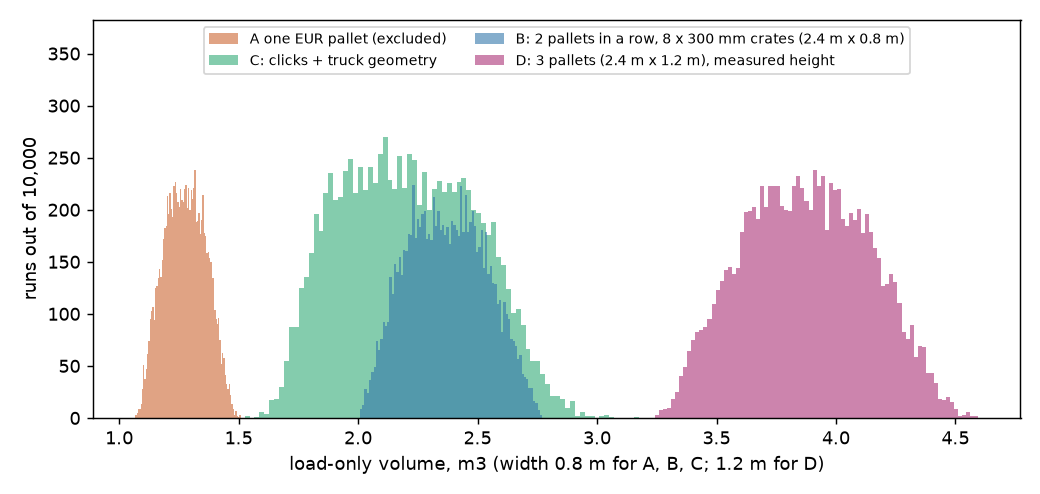

In [9]:
run('src/make_results.py')
from IPython.display import Image
Image('outputs/volume_hist.png')

## 7. Tests (fake box with known size + unit tests)

In [10]:
p = subprocess.run([sys.executable, '-m', 'pytest', 'tests', '-q'], capture_output=True, text=True); print(p.stdout[-600:])
assert p.returncode == 0, 'tests failed'

.............                                                            [100%]
13 passed in 0.23s

